# Vertical integration: RNA + ADT

Vertical integration combines modalities measured in the same cells. This tutorial is for RNA and surface protein, as in CITE-seq. It runs Matilda and sciPENN on `D11`, a CITE-seq dataset of 2,864 cells, and then on data in your own format.

Matilda and sciPENN run on Linux, Windows and macOS (Apple silicon). Or [open in Colab](https://colab.research.google.com/github/DSichang/scMultiBench/blob/main/notebooks/tutorial_vertical_rna_adt.ipynb): sections 1 to 4 take about 7 minutes there.

## 1. Install

pip may then print a note about restarting the kernel: no restart is needed, because the pins keep the numpy and pandas already installed.

In [1]:
import numpy, pandas
pins = f"numpy=={numpy.__version__} pandas=={pandas.__version__}"
%pip install -q "multibench-sc>=0.7.4" {pins}

## 2. Download the data and the environments

`mtb.data.fetch` downloads `D11` (11 MB) once. `mtb.env.install` downloads the environments for Matilda and sciPENN. On Linux the download is 1.1 GB on a computer without a GPU and 5.1 GB on one with a GPU. On Windows it is 0.3 GB and 2.8 GB. On macOS it is 0.7 GB.

In [2]:
import multibench as mtb

mtb.data.fetch("D11")
METHODS = ["Matilda", "sciPENN"]
envs = mtb.env.install(METHODS)

downloading D11 (11 MB) ...
[env] downloading env_sciPENN (cpu build) 473 MB ...
[env]   473 MB of 473 MB (21 MB/s)
[env] unpacking env_sciPENN ...
[env] downloading matilda (cpu build) 585 MB ...
[env]   585 MB of 585 MB (28 MB/s)
[env] unpacking matilda ...


## 3. Run the methods

`run` runs each method on `D11` and scores its output with the [scIB metrics](https://dsichang.github.io/scMultiBench/tutorials/evaluate/#what-each-metric-measures). The clustering metrics score how well the embedding's clusters and neighbourhoods match the cell types, and how separate the clusters are. Higher is better for every metric.

<details>
<summary>Details</summary>

`params={"Method": {"key": value}}` sets a method's parameters, and `mtb.params_for` lists them.

`mtb.load_run("out/D11")` reloads these results later.

</details>

In [3]:
res = mtb.run("D11", "vertical", methods=METHODS, out_dir="out/D11")
res.summary

[run] Matilda (vertical/D11) ...
[run]   -> scored (166.3s) ARI 0.850
[run] sciPENN (vertical/D11) ...
[run]   -> scored (48.0s) ARI 0.482


,method,status,ARI,NMI,ASW,iASW,iF1,cLISI,run_sec,caveat,reason
0,Matilda,scored,0.8503,0.8852,0.6617,0.678,0.8206,0.9993,166.3,,
1,sciPENN,scored,0.4820,0.6388,0.6332,0.669,0.5741,0.9811,48.0,,


## 4. Plot

`res.plot()` draws the scores as a bubble table. Circle size ranks the rows within each column and colour shows the value scaled per column, so a small gap can look large. `res.summary` has the values.

<details>
<summary>Details</summary>

Metrics are grouped by family: blue for clustering. Each family starts with an `Overall` bar: each row's mean rank over the family's metrics, scaled so that the lowest gets the shortest bar.

A column with fewer than two different values is drawn grey. A figure of one method is grey everywhere.

</details>

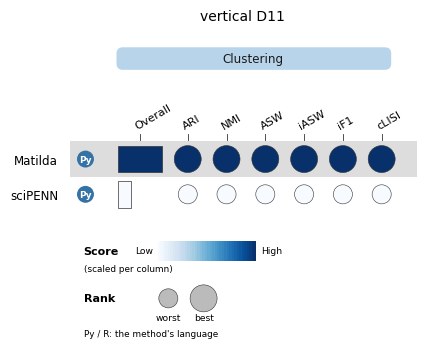

In [4]:
res.plot()

## 5. Your own data

Your data needs raw counts for both modalities and a cell type for each cell, in one `.h5ad` file.

Recipes cover [a 10x `.h5` file](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-10x-h5), [labels in a CSV file](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-labels-csv), [no labels](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-no-labels) and [several donors or samples](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-donors).

<details>
<summary>Details: export</summary>

The example keeps the protein names in `adata.uns["protein_names"]`. A DataFrame in `adata.obsm["protein"]` brings its own names in its columns.

</details>

The next cell writes a small example file, `my_file.h5ad`, from 60% of the cells of `D11`. Skip it for your own data.

In [5]:
mtb.data.write_example("D11")

wrote my_file.h5ad: 1,718 cells. RNA counts in X, protein counts in obsm["protein"], cell types in obs["celltype"].


Read your file. For your own data, change the file name marked `# <-`. On Colab, upload the file first: click the folder icon on the left, then the upload icon.

In [6]:
import anndata as ad

adata = ad.read_h5ad("my_file.h5ad")   # <- your file
adata

AnnData object with n_obs × n_vars = 1718 × 9822
    obs: 'celltype'
    uns: 'protein_names'
    obsm: 'protein'

Write the dataset folder. Change each name in quotes marked `# <-` to one the printout above lists for your file, with its prefix, as `"obs:celltype"` or `"obsm:protein"`.

In [7]:
NAME = "MYCITE"   # <- a new name for your own data
mtb.io.export_dataset(adata, "mydata/" + NAME,
                      rna="X",                # <- where the RNA counts are:
                                              #    "X" or "layer:counts"
                      adt="obsm:protein",     # <- where the proteins (ADT) are
                      labels="obs:celltype",  # <- the cell-type column
                      overwrite=True)
mtb.scan("mydata/" + NAME, "vertical", methods=METHODS)

[scan] 2 of 2 methods have their input files in MYCITE. 2 of 2 can run on this computer. MYCITE holds RNA and ADT.
[scan] Cells per file: rna.h5 1,718, adt.h5 1,718.


,method,modalities,runnable,reason,env,caveat
0,Matilda,rna+adt,True,,matilda,
1,sciPENN,rna+adt,True,,env_sciPENN,


In [ ]:
mine = mtb.run("mydata/" + NAME, "vertical", methods=METHODS,
               out_dir="out/" + NAME)
mine.summary

In [ ]:
mine.plot()

## 6. Stored results

The package ships stored results for 13 methods on `D11`. `load_results` reads them and `mtb.plot.bubble` draws them, without running anything.

<details>
<summary>Details</summary>

Scores of your runs differ a little from the stored ones: some methods, such as sciPENN, give a slightly different embedding on each run.

</details>

In [ ]:
stored = mtb.load_results("vertical", dataset="D11")
mtb.plot.bubble(stored)

## 7. Every method of this task

14 methods run this task. [This notebook](https://colab.research.google.com/github/DSichang/scMultiBench/blob/main/notebooks/tutorial_vertical_rna_adt_all.ipynb) runs them all. Its 13 environments download 24.5 GB on a computer without a GPU and 31.9 GB on one with a GPU.

## Troubleshooting

`res.summary[res.summary.status != "scored"]` lists each method that failed or was skipped. Its `reason` column ends with the method's error output.

<details>
<summary>Details</summary>

| symptom | fix |
|---|---|
| a method fails on a small dataset | `mtb.scan` names what the method needs from the data's size in its `caveat` column |

</details>

## Next steps

- [Run a method](https://dsichang.github.io/scMultiBench/tutorials/run/), [Score an embedding](https://dsichang.github.io/scMultiBench/tutorials/evaluate/), [Load and plot results](https://dsichang.github.io/scMultiBench/tutorials/plot/) and [Discover methods](https://dsichang.github.io/scMultiBench/tutorials/discover/).
- [Look at an embedding](https://dsichang.github.io/scMultiBench/tutorials/evaluate/#look-at-an-embedding) draws a method's embedding as a UMAP.
- The [interactive explorer](https://shiny.maths.usyd.edu.au/scMultiBench/) has the full benchmark's rankings, with no install needed.